# Customer Churn, Cohort & Retention Analysis

## Business Problem

A subscription-based company wants to understand customer churn and retention patterns to identify high-risk customer segments, explore how customer behaviour varies across groups, and develop data-driven recommendations for improving customer retention.

## Objectives

- Measure overall customer churn and explore transaction activity across customer cohorts.
- Identify customer segments with higher churn rates.
- Analyze customer behaviour across demographic and transaction-related attributes.
- Perform exploratory data analysis (EDA).
- Compare monthly transaction activity across customer cohorts.
- Investigate payment behaviour and its association with churn.
- Identify key business insights.
- Provide data-driven recommendations for improving customer retention.

## Tools & Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

## 1. Data Understanding

The project uses three datasets:

- `members` — customer demographic and registration information
- `train` — customer churn labels
- `transactions` — customer subscription and payment history

The datasets are loaded using relative file paths to keep the notebook portable and suitable for sharing through GitHub.

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
members = pd.read_csv("../Data/Raw/members_v3.csv")
train = pd.read_csv("../Data/Raw/train_v2.csv")
transactions = pd.read_csv("../Data/Raw/transactions_v2.csv")

In [3]:
print("MEMBERS:", members.shape)
print(members.columns.tolist())

print("\nTRAIN:", train.shape)
print(train.columns.tolist())

print("\nTRANSACTIONS:", transactions.shape)
print(transactions.columns.tolist())

MEMBERS: (6769473, 6)
['msno', 'city', 'bd', 'gender', 'registered_via', 'registration_init_time']

TRAIN: (970960, 2)
['msno', 'is_churn']

TRANSACTIONS: (1431009, 9)
['msno', 'payment_method_id', 'payment_plan_days', 'plan_list_price', 'actual_amount_paid', 'is_auto_renew', 'transaction_date', 'membership_expire_date', 'is_cancel']


### Dataset Structure

Three datasets were loaded for the analysis:

- **Members:** 67.69 lakh records and 6 columns, containing customer profile and registration information.
- **Train:** 9.71 lakh records and 2 columns, containing customer IDs and the churn label (`is_churn`).
- **Transactions:** 1.43 crore records and 9 columns, containing subscription, payment, renewal, cancellation, and transaction-date information.

The `train` dataset will serve as the primary customer-level dataset because it contains the churn outcome that will be analyzed. The `members` and `transactions` datasets will be used to enrich it with customer and behavioural information.

In [4]:
print("Missing values in MEMBERS:")
print(members.isnull().sum())

print("\nMissing values in TRAIN:")
print(train.isnull().sum())

print("\nMissing values in TRANSACTIONS:")
print(transactions.isnull().sum())

Missing values in MEMBERS:
msno                            0
city                            0
bd                              0
gender                    4429505
registered_via                  0
registration_init_time          0
dtype: int64

Missing values in TRAIN:
msno        0
is_churn    0
dtype: int64

Missing values in TRANSACTIONS:
msno                      0
payment_method_id         0
payment_plan_days         0
plan_list_price           0
actual_amount_paid        0
is_auto_renew             0
transaction_date          0
membership_expire_date    0
is_cancel                 0
dtype: int64


### Data Quality Check — Missing Values

The datasets were checked for missing values before analysis.

- `train` and `transactions` contain no missing values.
- `members` contains no missing values except for `gender`.
- The `gender` field has a substantial number of missing values, so these records should not be removed solely because gender is unavailable.

For analysis involving gender, missing values will be treated as `Unknown` rather than deleting customers. This preserves the customer records and avoids introducing unnecessary sampling bias.

In [5]:
print("Duplicate values in MEMBERS:", members.duplicated().sum())

print("\nDuplicate values in TRAIN:", train.duplicated().sum())

print("\nDuplicate values in TRANSACTIONS:", transactions.duplicated().sum())

Duplicate values in MEMBERS: 0

Duplicate values in TRAIN: 0

Duplicate values in TRANSACTIONS: 0


### Duplicate Record Check

The datasets were checked for exact duplicate rows.

- `members` contains no duplicate records.
- `train` contains no duplicate records.
- `transactions` contains no duplicate records.

Therefore, no duplicate rows need to be removed at this stage.

In [6]:
print("Unique customers in MEMBERS:", members["msno"].nunique())
print("Unique customers in TRAIN:", train["msno"].nunique())
print("Unique customers in TRANSACTIONS:", transactions["msno"].nunique())

Unique customers in MEMBERS: 6769473
Unique customers in TRAIN: 970960
Unique customers in TRANSACTIONS: 1197050


### Customer ID Uniqueness

The number of unique customer IDs (`msno`) was checked across all three datasets.

- `members` contains **67.69 lakh unique customers**.
- `train` contains **9.71 lakh unique customers**.
- `transactions` contains **11.97 lakh unique customers**.

Although the `transactions` dataset contains 1.43 crore records, it represents 11.97 lakh unique customers because individual customers can have multiple transaction records.

In [7]:
print("Duplicate customer IDs in MEMBERS:", members["msno"].duplicated().sum())
print("Duplicate customer IDs in TRAIN:", train["msno"].duplicated().sum())

Duplicate customer IDs in MEMBERS: 0
Duplicate customer IDs in TRAIN: 0



The customer ID (`msno`) was checked for duplicates in the customer-level datasets.

- `members` contains no duplicate customer IDs.
- `train` contains no duplicate customer IDs.

Therefore, each customer appears only once in both datasets, making them suitable for customer-level analysis and merging.

In [8]:
train_id = set(train["msno"])
mem_id = set(members["msno"])
tran_id = set(transactions["msno"])

print("Train customers missing from MEMBERS:",
      len(train_id - mem_id))

print("Train customers missing from TRANSACTIONS:",
      len(train_id - tran_id))

Train customers missing from MEMBERS: 109993
Train customers missing from TRANSACTIONS: 37382


### Customer ID Consistency Check

Customer IDs were compared across the datasets to identify `train` customers without corresponding records in the supporting datasets.

- **109,993 customers** in `train` are not present in `members`.
- **37,382 customers** in `train` are not present in `transactions`.

These unmatched customers will be retained in the analysis rather than removed, since excluding them could affect the representativeness of the churn analysis. The impact of missing transaction records will be investigated further.

In [9]:
missing_members = train_id - mem_id
missing_transactions = train_id - tran_id

print("Overall churn rate:", train["is_churn"].mean() * 100)

print("Churn rate of TRAIN customers not present in MEMBERS:", train[train["msno"].isin(missing_members)]["is_churn"].mean() * 100)

print("Churn rate of TRAIN customers not present in TRANSACTIONS:", train[train["msno"].isin(missing_transactions)]["is_churn"].mean() * 100)

Overall churn rate: 8.994191315811156
Churn rate of TRAIN customers not present in MEMBERS: 5.347613029920086
Churn rate of TRAIN customers not present in TRANSACTIONS: 78.74110534481837


### Churn Rate Validation for Unmatched Customers

The churn rate was compared across the full `train` population and customers who could not be matched to the supporting datasets.

- Overall churn rate: **8.99%**
- Churn rate among customers present in `train` but missing from `members`: **5.35%**
- Churn rate among customerspresent in `train`but  missing from `transactions`: **78.74%**

Customers missing from the transaction dataset show a substantially higher churn rate than the overall population. Therefore, these records should not be removed without further investigation, as doing so could materially affect the churn analysis.

In [10]:
print("Customers missing from TRANSACTIONS:", len(missing_transactions))

print("Churned customers in this group:", (train[train["msno"].isin(missing_transactions)]["is_churn"]== 1).sum())

print("Not churned customers in this group:", (train[train["msno"].isin(missing_transactions)]["is_churn"] == 0).sum())

Customers missing from TRANSACTIONS: 37382
Churned customers in this group: 29435
Not churned customers in this group: 7947


### Churn Profile of Customers Missing from Transactions

The 37,382 `train` customers without matching transaction records were investigated further.

- **29,435 customers** in this group churned.
- **7,947 customers** did not churn.
- This corresponds to a churn rate of approximately **78.74%**.

The substantially higher churn rate among customers without transaction records indicates that these customers should not be removed from the analysis without further consideration, as doing so could materially affect the churn results.

In [11]:
print("Earliest transaction date:", transactions["transaction_date"].min())
print("Latest transaction date:", transactions["transaction_date"].max())

print("Earliest membership expiry date:", transactions["membership_expire_date"].min())
print("Latest membership expiry date:", transactions["membership_expire_date"].max())

Earliest transaction date: 20150101
Latest transaction date: 20170331
Earliest membership expiry date: 20160419
Latest membership expiry date: 20361015


### Date Range Check

The transaction data covers records from **1 January 2015 to 31 March 2017**.

Membership expiry dates range from **19 April 2016 to 15 January 2036**. The unusually distant expiry date will be retained for now and considered if it affects any subsequent time-based analysis.

## 2. Data Cleaning

The datasets were checked for missing values, duplicate records, customer ID consistency, and date ranges before analysis.

Date fields are stored as numeric values in `YYYYMMDD` format and will be converted to datetime format to support time-based analysis, including churn, cohort, and retention analysis.

In [12]:
members["registration_init_time"] = pd.to_datetime(members["registration_init_time"], format="%Y%m%d")

transactions["transaction_date"] = pd.to_datetime(transactions["transaction_date"], format="%Y%m%d")

transactions["membership_expire_date"] = pd.to_datetime(transactions["membership_expire_date"], format="%Y%m%d")

In [13]:
customer_data = train.merge(
    members,
    on="msno",
    how="left"
)

print("Rows:", len(customer_data))
print("Columns:", len(customer_data.columns))

Rows: 970960
Columns: 7


### Customer-Level Dataset

The churn dataset `train` was used as the base population and merged with customer profile information from `members` using the customer ID (`msno`).

A left join was used to retain all customers in the churn dataset, including customers without a matching profile record.

The resulting dataset contains 9.71 lakh customer records and 7 columns.

In [14]:
customer_data["gender"] = customer_data["gender"].fillna("Unknown")

### Handling Missing Gender Values

The `gender` field contained a substantial number of missing values. Rather than removing these customer records, missing values were categorized as `Unknown` to preserve the full customer population for analysis.

In [15]:
transaction_features = transactions.groupby("msno").agg(
    total_transactions=("msno", "size"),
    total_amount_paid=("actual_amount_paid", "sum"),
    avg_amount_paid=("actual_amount_paid", "mean"),
    avg_plan_days=("payment_plan_days", "mean"),
    auto_renew_rate=("is_auto_renew", "mean"),
    cancellation_rate=("is_cancel", "mean"),
    unique_payment_methods=("payment_method_id", "nunique"),
    first_transaction_date=("transaction_date", "min"),
    last_transaction_date=("transaction_date", "max")
).reset_index()

print("Rows:", len(transaction_features))
print("Columns:", len(transaction_features.columns))

transaction_features.head()

Rows: 1197050
Columns: 10


,msno,total_transactions,total_amount_paid,avg_amount_paid,avg_plan_days,auto_renew_rate,cancellation_rate,unique_payment_methods,first_transaction_date,last_transaction_date
0,+++IZseRRiQS9aaSkH6cMYU6bGDcxUieAi/tH67sC5s=,1,1599,1599.0,395.0,0.0,0.0,1,2016-10-23,2016-10-23
1,+++hVY1rZox/33YtvDgmKA2Frg/2qhkz12B9ylCvh8o=,1,99,99.0,30.0,1.0,0.0,1,2017-03-15,2017-03-15
2,+++l/EXNMLTijfLBa8p2TUVVVp2aFGSuUI/h7mLmthw=,2,298,149.0,30.0,1.0,0.0,1,2017-02-28,2017-03-31
3,+++snpr7pmobhLKUgSHTv/mpkqgBT0tQJ0zQj6qKrqc=,1,149,149.0,30.0,1.0,0.0,1,2017-03-26,2017-03-26
4,++/9R3sX37CjxbY/AaGvbwr3QkwElKBCtSvVzhCBDOk=,1,149,149.0,30.0,1.0,0.0,1,2017-03-15,2017-03-15


### Transaction-Level Feature Engineering

The transaction history was aggregated to the customer level using `msno`.

The resulting features capture transaction frequency, spending behaviour, subscription duration, renewal behaviour, cancellation behaviour, payment-method diversity, and transaction timing. These features will be used to compare customer behaviour between churned and retained customers.

In [16]:
customer_data = customer_data.merge(
    transaction_features,
    on="msno",
    how="left"
)

print("Rows:", len(customer_data))
print("Columns:", len(customer_data.columns))

Rows: 970960
Columns: 16


### Merging Transaction Features

The customer-level transaction features were merged into `customer_data` using the customer ID (`msno`).

A left join was used to retain all **9.71 lakh customers** in the churn dataset, including customers without matching transaction records.

The resulting dataset contains **16 columns**, combining churn labels, customer profile information, and transaction-based behavioural features.

In [17]:
print(customer_data[
    [
        "total_transactions",
        "total_amount_paid",
        "avg_amount_paid",
        "avg_plan_days",
        "auto_renew_rate",
        "cancellation_rate",
        "unique_payment_methods",
        "first_transaction_date",
        "last_transaction_date"
    ]
].isnull().sum())

total_transactions        37382
total_amount_paid         37382
avg_amount_paid           37382
avg_plan_days             37382
auto_renew_rate           37382
cancellation_rate         37382
unique_payment_methods    37382
first_transaction_date    37382
last_transaction_date     37382
dtype: int64


### Missing Transaction Features After Merge

The merged dataset contains **37,382 missing values** across each transaction-derived feature.

This matches the number of `train` customers without corresponding records in the `transactions` dataset. These missing values therefore represent customers for whom no transaction history is available in the dataset, rather than random missing observations.

These customers will be handled separately from customers with recorded transaction history rather than being automatically removed.

In [18]:
reference_date = transactions["transaction_date"].max()

customer_data["transaction_span_days"] = (customer_data["last_transaction_date"] - customer_data["first_transaction_date"]).dt.days

customer_data["recency_days"] = (reference_date  - customer_data["last_transaction_date"]).dt.days

print("Reference date:", reference_date)

Reference date: 2017-03-31 00:00:00


### Tenure and Recency Features

Two time-based behavioural features were created from transaction history.

- `transaction_span_days` measures the number of days between a customer's first and last recorded transaction.
- `recency_days` measures the number of days between the customer's last recorded transaction and the final transaction date in the dataset (31 March 2017).

These features will be used to examine whether customer activity duration and recency are associated with churn.

In [19]:
print("Minimum age:", customer_data["bd"].min())
print("Maximum age:", customer_data["bd"].max())

print("Customers with age <= 0:",
      (customer_data["bd"] <= 0).sum())

print("Customers with age > 100:",
      (customer_data["bd"] > 100).sum())

Minimum age: -3152.0
Maximum age: 2016.0
Customers with age <= 0: 473798
Customers with age > 100: 454


### Age Data Quality Check

The `bd` column was examined for implausible age values.

- The recorded values range from **−3,152 to 2,016**.
- **473,798 records** have values less than or equal to zero.
- **454 records** have values above 100.

These results indicate substantial data-quality issues in the age field. Invalid or implausible values will be treated as missing before age-based segmentation to avoid misleading conclusions.

In [20]:
customer_data.loc[
    (customer_data["bd"] <= 0) | (customer_data["bd"] > 100),
    "bd"
] = np.nan

In [21]:
print("Missing ages after cleaning:", customer_data["bd"].isnull().sum())

Missing ages after cleaning: 584245


### Handling Invalid Age Values

Values in the `bd` column that were less than or equal to zero or greater than 100 were replaced with missing values (`NaN`).

After cleaning, 584,245 customer records have missing age values. These records are retained in the dataset, and their other customer information remains available for analysis.

In [22]:
customer_data["has_transaction_history"] = (
    customer_data["total_transactions"].notna().astype(int)
)

print(customer_data["has_transaction_history"].value_counts())

has_transaction_history
1    933578
0     37382
Name: count, dtype: int64


### Identifying Customers with Transaction History

A binary indicator, `has_transaction_history`, was created to distinguish customers with recorded transaction history from those without matching transaction records.

- **933,578 customers** have transaction history.
- **37,382 customers** have no matching transaction records.

This indicator allows the analysis to compare churn patterns between the two groups while retaining all customers in the dataset.

In [23]:
total_customers = len(customer_data)

churned_customers = customer_data["is_churn"].sum()

overall_churn_rate = (
    churned_customers / total_customers
) * 100

print("Total customers:", total_customers)
print("Churned customers:", churned_customers)
print("Overall churn rate:", round(overall_churn_rate, 2), "%")

Total customers: 970960
Churned customers: 87330
Overall churn rate: 8.99 %


### Overall Customer Churn Rate

The dataset contains 970,960 customers, of whom 87,330 are labelled as churned.

The overall churn rate is **8.99%**, calculated as the proportion of customers labelled as churned relative to the total customer population.

This rate serves as the baseline for comparing churn across customer segments and identifying groups with higher churn rates.

In [24]:
churn_by_history = customer_data.groupby(
    "has_transaction_history"
)["is_churn"].mean() * 100

print(churn_by_history)

has_transaction_history
0    78.741105
1     6.201410
Name: is_churn, dtype: float64


### Churn Rate by Transaction History

Customers were segmented according to whether matching transaction records were available.

- Customers without matching transaction records have a churn rate of **78.74%**.
- Customers with transaction history have a churn rate of **6.20%**.
- The overall churn rate is **8.99%**.

The churn rate is substantially higher among customers without matching transaction records. This indicates that transaction-history availability is strongly associated with the churn label in this dataset. These customers should be retained in the analysis to avoid understating churn.

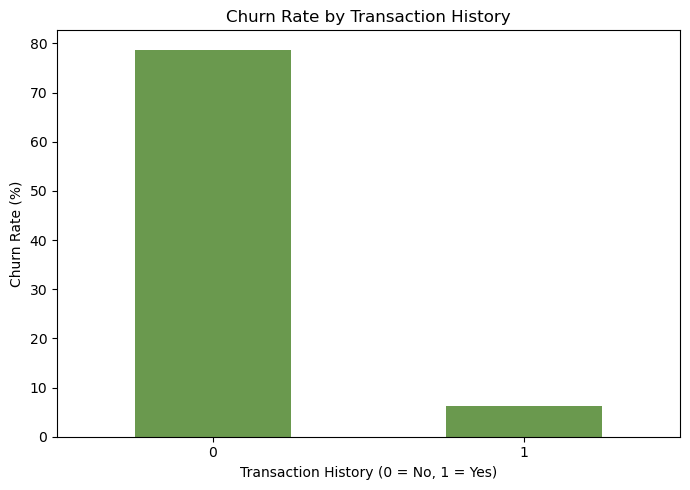

In [25]:
churn_by_history.plot(
    kind="bar",
    figsize=(7, 5),
    color=["#6A994E"]
)

plt.title("Churn Rate by Transaction History")
plt.xlabel("Transaction History (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation

The bar chart highlights a substantial difference in churn rates based on transaction-history availability. Customers without matching transaction records have a churn rate of 78.74%, compared with 6.20% among customers with recorded transaction history.

This association makes transaction-history availability an important factor to consider when interpreting churn results. However, the absence of a matching record does not necessarily mean that a customer never transacted, and the relationship should not be interpreted as causal.

In [26]:
churn_by_gender = customer_data.groupby('gender')["is_churn"].mean() * 100

print(churn_by_gender)

gender
Unknown     6.355757
female     12.986590
male       12.903730
Name: is_churn, dtype: float64


### Churn Rate by Gender

Customers were grouped by gender to compare their churn rates.

- Female customers have a churn rate of **12.99%**.
- Male customers have a churn rate of **12.90%**.
- Customers with unknown gender have a churn rate of **6.36%**.

Female and male customers show nearly identical churn rates. The lower churn rate among customers with unknown gender should be interpreted cautiously, as this group may differ in data completeness or customer composition. These results show an association and do not establish that gender causes churn.

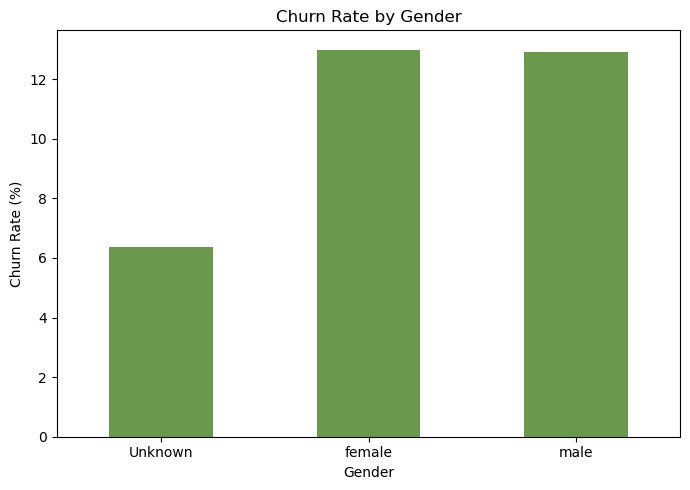

In [27]:
churn_by_gender.plot(
    kind="bar",
    figsize=(7, 5),
    color="#6A994E"
)

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation

The chart shows that female and male customers have nearly identical churn rates (12.99% and 12.90%, respectively). Customers with unknown gender have a lower churn rate of 6.36%.

Gender-based churn differences are minimal between female and male customers. The lower rate among customers with unknown gender should be interpreted cautiously, as missing demographic information may reflect differences in the customer population. Further analysis is needed before drawing business conclusions from this pattern.

In [28]:
customer_data["age_group"] = pd.cut(
    customer_data["bd"],
    bins=[0, 18, 25, 35, 50, 100],
    labels=["Under 18", "18–25", "26–35", "36–50", "51–100"],
    include_lowest=True
)

churn_by_age = (
    customer_data.groupby("age_group", observed=False)["is_churn"].mean() * 100
)

print(churn_by_age)

age_group
Under 18    27.067711
18–25       16.766901
26–35       10.919266
36–50       10.384956
51–100       8.608907
Name: is_churn, dtype: float64


### Churn Rate by Age Group

Customers were segmented into age groups to examine differences in churn rates.

- Customers under 18 have the highest churn rate at **27.07%**.
- The churn rate decreases to **16.77%** among customers aged 18–25.
- Customers aged 26–35 and 36–50 have similar churn rates of **10.92%** and **10.38%**, respectively.
- Customers aged 51–100 have the lowest churn rate at **8.61%**.

The results indicate an association between age group and churn, with younger customers showing higher churn rates. This pattern may help identify customer segments for further investigation, although it does not establish that age causes churn.

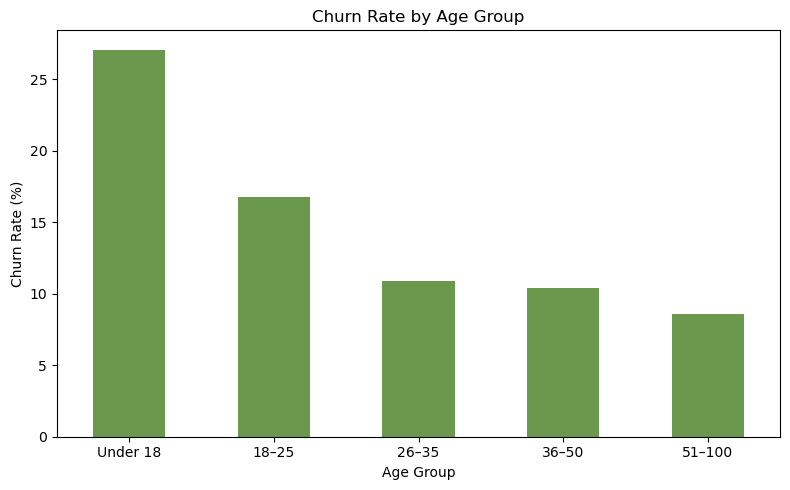

In [29]:
churn_by_age.plot(
    kind="bar",
    figsize=(8, 5),
    color="#6A994E"
)

plt.title("Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation

The chart shows a decreasing trend in churn rates across the age groups.

- Customers under 18 have the highest churn rate at 27.07%.
- Customers aged 18–25 have a churn rate of 16.77%.
- Churn rates decline to approximately 10–11% among customers aged 26–50.
- Customers aged 51–100 have the lowest churn rate at 8.61%.

These results suggest that younger customer segments may require closer investigation to understand the factors associated with higher churn. However, age alone does not establish the cause of churn, and the results should be interpreted alongside other customer characteristics.

In [30]:
churn_by_renewal = (
    customer_data.groupby("auto_renew_rate")["is_churn"].mean() * 100
)

print(churn_by_renewal)

auto_renew_rate
0.000000     30.261089
0.083333    100.000000
0.160714    100.000000
0.200000     60.000000
0.227273    100.000000
0.250000     75.000000
0.285714    100.000000
0.307692    100.000000
0.333333     52.739726
0.400000     66.666667
0.500000     40.899358
0.600000     83.333333
0.625000     50.000000
0.640000    100.000000
0.666667     46.746988
0.750000     45.454545
0.777778    100.000000
0.800000     41.379310
0.833333     22.784810
0.857143     80.000000
0.866667    100.000000
0.875000     80.000000
0.882353      0.000000
0.888889     88.888889
0.900000    100.000000
0.909091    100.000000
0.916667    100.000000
0.923077     81.818182
0.928571     50.000000
0.933333    100.000000
0.937500     75.000000
0.941176     60.000000
0.945946    100.000000
0.947368      0.000000
0.950000    100.000000
0.952381     75.000000
0.954545    100.000000
0.956522    100.000000
0.958333    100.000000
0.961538    100.000000
0.962963    100.000000
0.968750    100.000000
0.970588    100.00

In [31]:
customer_data["auto_renew_group"] = np.where(
    customer_data["auto_renew_rate"] == 1,
    "Always auto-renew",
    "Not always auto-renew"
)

customer_data.loc[
    customer_data["auto_renew_rate"].isna(),
    "auto_renew_group"
] = "No transaction history"

churn_by_renewal = (
    customer_data.groupby("auto_renew_group")["is_churn"].mean() * 100
)

print(churn_by_renewal)

auto_renew_group
Always auto-renew          3.791242
No transaction history    78.741105
Not always auto-renew     30.725401
Name: is_churn, dtype: float64


### Churn Rate by Auto-Renewal Behaviour

Customers were segmented according to their recorded auto-renewal behaviour.

- Customers whose recorded transactions always had auto-renew enabled have a churn rate of **3.79%**.
- Customers whose transactions did not always have auto-renew enabled have a churn rate of **30.73%**.
- Customers without matching transaction records have a churn rate of **78.74%**.

The results show an association between auto-renewal behaviour and churn. Customers with consistently enabled auto-renewal have substantially lower churn rates. However, this relationship does not establish causation, and the group without transaction records is considered separately because their renewal behaviour is unknown.

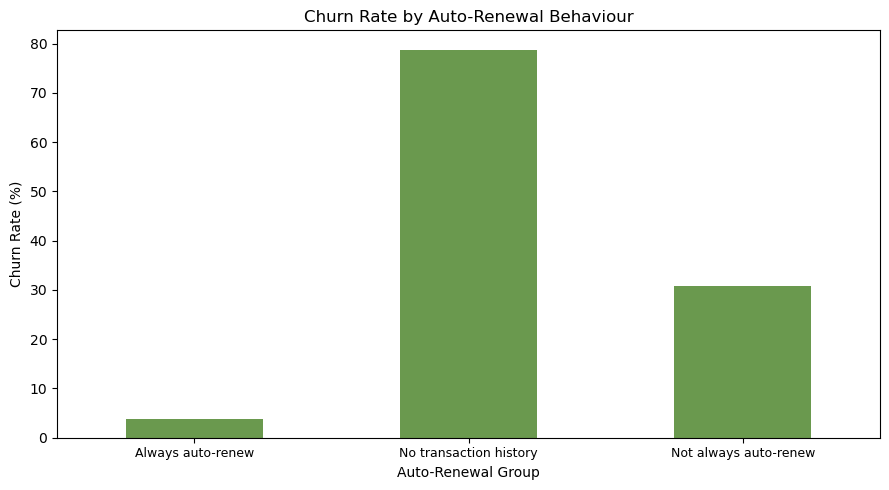

In [32]:
churn_by_renewal.plot(
    kind="bar",
    figsize=(9, 5),
    color="#6A994E"
)

plt.title("Churn Rate by Auto-Renewal Behaviour")
plt.xlabel("Auto-Renewal Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

### Interpretation

Customers whose recorded transactions always had auto-renew enabled have the lowest churn rate (3.79%), compared with 30.73% for customers whose transactions did not always have auto-renew enabled.

Customers without matching transaction records have the highest churn rate (78.74%). Their renewal behaviour is unknown, so they are shown as a separate group.

These results suggest that consistent auto-renewal behaviour is associated with lower churn. Further analysis would be needed to determine whether auto-renewal itself contributes to retention.

In [33]:
customer_data["plan_duration_group"] = pd.cut(
    customer_data["avg_plan_days"],
    bins=[0, 30, 90, 180, float("inf")],
    labels=["Up to 30 days", "31–90 days", "91–180 days", "Over 180 days"],
    include_lowest=True
).astype("object")

customer_data.loc[
    customer_data["avg_plan_days"].isna(),
    "plan_duration_group"
] = "No transaction history"

churn_by_plan = (
    customer_data.groupby(
        "plan_duration_group",
        observed=False
    )["is_churn"].mean() * 100
)

print(churn_by_plan)

plan_duration_group
31–90 days                89.468016
91–180 days               97.922268
No transaction history    78.741105
Over 180 days             99.559887
Up to 30 days              4.395712
Name: is_churn, dtype: float64


In [34]:
print(
    customer_data["plan_duration_group"].value_counts(
        dropna=False
    )
)

plan_duration_group
Up to 30 days             915301
No transaction history     37382
Over 180 days               9543
31–90 days                  4643
91–180 days                 4091
Name: count, dtype: int64


In [35]:
print(
    customer_data.groupby(
        "plan_duration_group",
        observed=False
    )["avg_plan_days"].describe()
)

                           count        mean        std         min     25%  \
plan_duration_group                                                           
31–90 days                4643.0   78.008200  15.361156   30.120000   61.75   
91–180 days               4091.0  153.584272  33.687468   92.333333  112.50   
No transaction history       0.0         NaN        NaN         NaN     NaN   
Over 180 days             9543.0  313.707255  99.242769  180.500000  195.00   
Up to 30 days           915301.0   29.987567   0.451005    0.000000   30.00   

                          50%    75%    max  
plan_duration_group                          
31–90 days               90.0   90.0   90.0  
91–180 days             180.0  180.0  180.0  
No transaction history    NaN    NaN    NaN  
Over 180 days           360.0  410.0  450.0  
Up to 30 days            30.0   30.0   30.0  


In [36]:
churn_counts_by_plan = pd.crosstab(
    customer_data["plan_duration_group"],
    customer_data["is_churn"]
)

print(churn_counts_by_plan)

is_churn                     0      1
plan_duration_group                  
31–90 days                 489   4154
91–180 days                 85   4006
No transaction history    7947  29435
Over 180 days               42   9501
Up to 30 days           875067  40234


In [37]:
registration_churn = customer_data.groupby(
    "registered_via",
    dropna=False
).agg(
    total_customers=("is_churn", "size"),
    churn_rate=("is_churn", "mean")
).reset_index()

registration_churn["churn_rate"] = (
    registration_churn["churn_rate"] * 100
).round(2)

print(registration_churn.sort_values(
    "churn_rate",
    ascending=False
))

   registered_via  total_customers  churn_rate
1             4.0            52744       23.10
0             3.0           106459       17.23
3             9.0           235689       12.68
4            13.0             3391        9.88
5             NaN           109993        5.35
2             7.0           462684        4.47


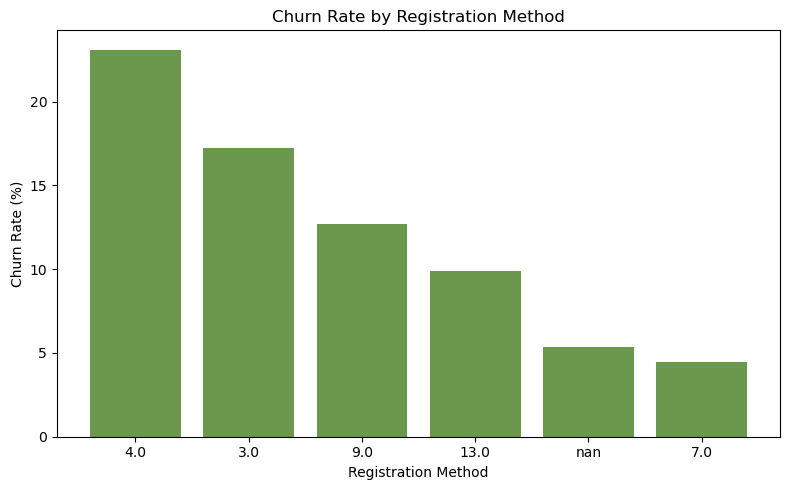

In [38]:
registration_churn_sorted = registration_churn.sort_values(
    "churn_rate",
    ascending=False
)

plt.figure(figsize=(8, 5))
plt.bar(
    registration_churn_sorted["registered_via"].astype(str),
    registration_churn_sorted["churn_rate"],
    color="#6A994E"
)

plt.title("Churn Rate by Registration Method")
plt.xlabel("Registration Method")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

### Churn Rate by Registration Method

Churn rates vary across registration methods. Method 4 has the highest observed churn rate at 23.10%, followed by method 3 at 17.23%. Method 7 has the lowest rate at 4.47%.

The group with missing registration information has a churn rate of 5.35%. These differences indicate an association between registration method and churn, but do not establish causation. The registration-method codes are retained as categorical values because their meanings have not yet been verified.

In [40]:
city_churn = customer_data.groupby("city", dropna=False).agg(
    total_customers=("is_churn", "size"),churn_rate=("is_churn", "mean")).reset_index()

city_churn["churn_rate"] = ( city_churn["churn_rate"] * 100).round(2)

print(
    city_churn.sort_values(
        "total_customers",
        ascending=False
    ).to_string(index=False)
)

 city  total_customers  churn_rate
  1.0           442598        6.41
  NaN           109993        5.35
 13.0            97136       12.30
  5.0            70706       13.20
  4.0            47227       12.90
 15.0            43187       12.82
 22.0            41991       12.58
  6.0            26066       12.88
 14.0            20013       11.84
 12.0            11383       13.92
  9.0             9526       12.60
 11.0             9138       11.99
 18.0             7792       11.72
  8.0             7589       13.45
 10.0             6470       13.26
 17.0             5476       10.43
 21.0             5199       14.71
  3.0             5057       13.29
  7.0             2652       11.16
 16.0              944       11.02
 20.0              677       10.64
 19.0              140       12.14


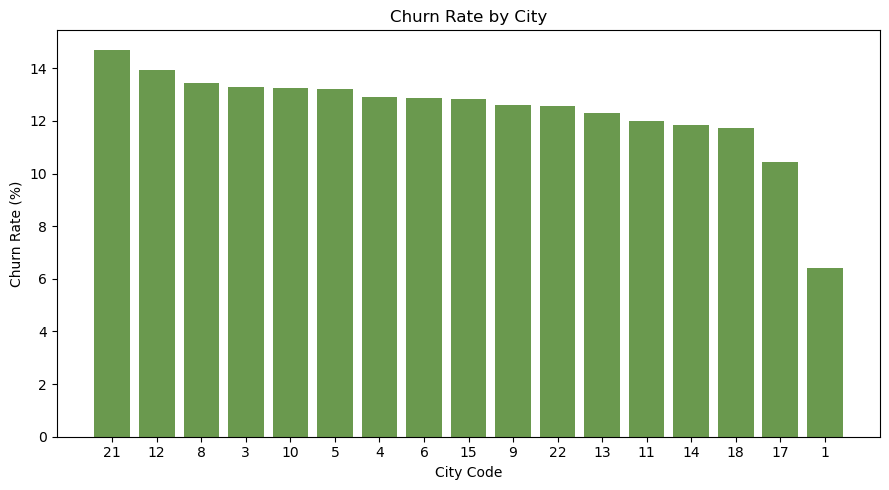

In [41]:
city_churn_plot = city_churn[
    city_churn["city"].notna()
    & (city_churn["total_customers"] >= 5000)
].sort_values("churn_rate", ascending=False)

plt.figure(figsize=(9, 5))
plt.bar(
    city_churn_plot["city"].astype(int).astype(str),
    city_churn_plot["churn_rate"],
    color="#6A994E"
)

plt.title("Churn Rate by City")
plt.xlabel("City Code")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

### Churn Rate by City

Churn rates vary across the recorded city codes. Among the cities included in the comparison, City 21 has the highest churn rate at 14.71%, while City 1 has the lowest at 6.41%.

The chart includes only cities with at least 5,000 customers to reduce the influence of small groups. Since the dataset provides city codes rather than verified city names, the results are interpreted using these codes. The observed differences indicate an association between city and churn, but do not establish causation.

In [42]:
customer_data.groupby("is_churn")["avg_amount_paid"].describe()

,count,mean,std,min,25%,50%,75%,max
is_churn,,,,,,,,
0,875683.0,129.000511,29.039643,0.0,99.0,149.0,149.0,1520.0
1,57895.0,367.029821,471.655988,0.0,149.0,149.0,400.0,2000.0


<Figure size 700x500 with 0 Axes>

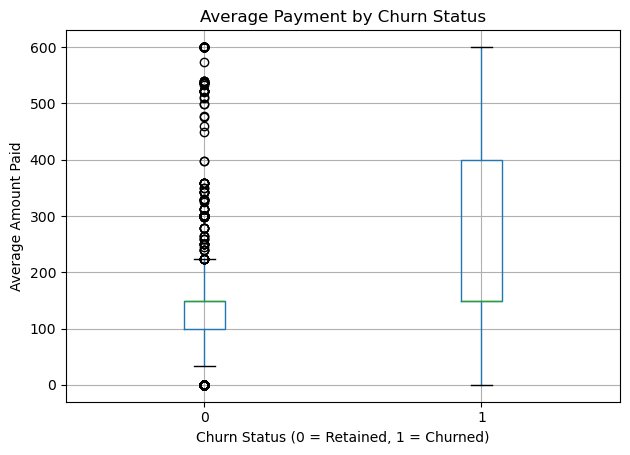

In [43]:
payment_data = customer_data[
    customer_data["avg_amount_paid"].notna()
].copy()

upper_limit = payment_data["avg_amount_paid"].quantile(0.99)

payment_data["avg_amount_paid_capped"] = (
    payment_data["avg_amount_paid"].clip(upper=upper_limit)
)

plt.figure(figsize=(7, 5))
payment_data.boxplot(
    column="avg_amount_paid_capped",
    by="is_churn"
)

plt.title("Average Payment by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status (0 = Retained, 1 = Churned)")
plt.ylabel("Average Amount Paid")
plt.tight_layout()
plt.show()

### Average Payment by Churn Status

The median average payment is 149 for both retained and churned customers. However, churned customers show a wider distribution of average payments, with the 75th percentile reaching 400 compared with 149 for retained customers.

The higher mean among churned customers (367.03 versus 129.00) suggests that some customers in this group have substantially higher average payments. Since these values are calculated from available transaction histories, the comparison does not establish that payment amounts cause churn.

In [44]:
customer_data.groupby("is_churn")["total_transactions"].describe()

,count,mean,std,min,25%,50%,75%,max
is_churn,,,,,,,,
0,875683.0,1.163050,1.048576,1.0,1.0,1.0,1.0,61.0
1,57895.0,1.961707,3.072236,1.0,1.0,1.0,2.0,208.0


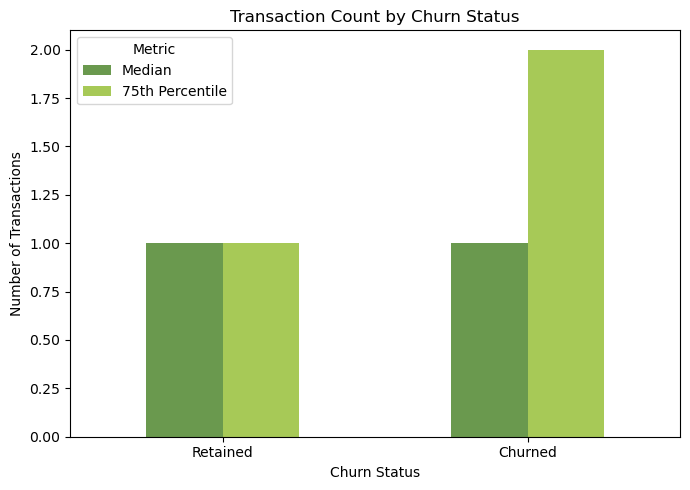

In [45]:
transaction_summary = (
    customer_data.groupby("is_churn")["total_transactions"]
    .quantile([0.50, 0.75])
    .unstack()
)

transaction_summary.index = ["Retained", "Churned"]
transaction_summary.columns = ["Median", "75th Percentile"]

transaction_summary.plot(
    kind="bar",
    figsize=(7, 5),
    color=["#6A994E", "#A7C957"]
)

plt.title("Transaction Count by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

In [46]:
print("Registration date range:")
print(customer_data["registration_init_time"].min())
print(customer_data["registration_init_time"].max())

print("\nTransaction date range:")
print(transactions["transaction_date"].min())
print(transactions["transaction_date"].max())

Registration date range:
2004-03-26 00:00:00
2017-04-24 00:00:00

Transaction date range:
2015-01-01 00:00:00
2017-03-31 00:00:00


In [47]:
customer_data["registration_month"] = (
    customer_data["registration_init_time"]
    .dt.to_period("M")
)

customer_data["registration_month"].value_counts().sort_index()

registration_month
2004-03     1324
2004-04      409
2004-05      130
2004-06      167
2004-07     1499
           ...  
2016-12    15549
2017-01    15078
2017-02    17095
2017-03     1056
2017-04        1
Freq: M, Name: count, Length: 158, dtype: int64

In [49]:
transactions["transaction_month"] = (
    transactions["transaction_date"].dt.to_period("M")
)

monthly_activity = transactions[
    ["msno", "transaction_month"]
].drop_duplicates()

monthly_activity.head()

,msno,transaction_month
0,++6eU4LsQ3UQ20ILS7d99XK8WbiVgbyYL4FUgzZR134=,2017-01
1,++lvGPJOinuin/8esghpnqdljm6NXS8m8Zwchc7gOeA=,2015-08
2,+/GXNtXWQVfKrEDqYAzcSw2xSPYMKWNj22m+5XkVQZc=,2017-03
3,+/w1UrZwyka4C9oNH3+Q8fUf3fD8R3EwWrx57ODIsqk=,2017-03
4,+00PGzKTYqtnb65mPKPyeHXcZEwqiEzktpQksaaSC3c=,2017-03


In [50]:
# Identify each customer's first observed transaction month
first_activity = (monthly_activity.groupby("msno")["transaction_month"].min().rename("cohort_month"))

monthly_activity = monthly_activity.join(
    first_activity,
    on="msno")

monthly_activity.head()

,msno,transaction_month,cohort_month
0,++6eU4LsQ3UQ20ILS7d99XK8WbiVgbyYL4FUgzZR134=,2017-01,2017-01
1,++lvGPJOinuin/8esghpnqdljm6NXS8m8Zwchc7gOeA=,2015-08,2015-01
2,+/GXNtXWQVfKrEDqYAzcSw2xSPYMKWNj22m+5XkVQZc=,2017-03,2017-03
3,+/w1UrZwyka4C9oNH3+Q8fUf3fD8R3EwWrx57ODIsqk=,2017-03,2017-03
4,+00PGzKTYqtnb65mPKPyeHXcZEwqiEzktpQksaaSC3c=,2017-03,2017-03


In [52]:
monthly_activity["months_since_cohort"] = (
    (monthly_activity["transaction_month"].astype("int64"))
    - (monthly_activity["cohort_month"].astype("int64"))
)

monthly_activity.head()

,msno,transaction_month,cohort_month,months_since_cohort
0,++6eU4LsQ3UQ20ILS7d99XK8WbiVgbyYL4FUgzZR134=,2017-01,2017-01,0
1,++lvGPJOinuin/8esghpnqdljm6NXS8m8Zwchc7gOeA=,2015-08,2015-01,7
2,+/GXNtXWQVfKrEDqYAzcSw2xSPYMKWNj22m+5XkVQZc=,2017-03,2017-03,0
3,+/w1UrZwyka4C9oNH3+Q8fUf3fD8R3EwWrx57ODIsqk=,2017-03,2017-03,0
4,+00PGzKTYqtnb65mPKPyeHXcZEwqiEzktpQksaaSC3c=,2017-03,2017-03,0


In [53]:
cohort_activity = monthly_activity.pivot_table(
    index="cohort_month",
    columns="months_since_cohort",
    values="msno",
    aggfunc="nunique"
)

cohort_activity.head()

months_since_cohort,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
cohort_month,,,,,,,,,,,,,,,,,,,,,
2015-01,492.0,443.0,443.0,440.0,439.0,437.0,436.0,435.0,433.0,434.0,...,2.0,3.0,1.0,1.0,4.0,4.0,4.0,8.0,9.0,270.0
2015-02,145.0,122.0,124.0,123.0,123.0,122.0,122.0,121.0,121.0,123.0,...,2.0,1.0,1.0,3.0,2.0,1.0,1.0,4.0,79.0,NaN
2015-03,913.0,876.0,875.0,876.0,874.0,873.0,866.0,863.0,869.0,781.0,...,2.0,1.0,2.0,1.0,4.0,3.0,26.0,586.0,NaN,NaN
2015-04,222.0,194.0,191.0,191.0,191.0,188.0,187.0,188.0,165.0,35.0,...,5.0,6.0,5.0,6.0,8.0,11.0,130.0,NaN,NaN,NaN
2015-05,411.0,379.0,379.0,379.0,374.0,371.0,377.0,333.0,103.0,80.0,...,3.0,NaN,NaN,2.0,16.0,252.0,NaN,NaN,NaN,NaN


In [54]:
cohort_sizes = cohort_activity[0]

cohort_percentages = cohort_activity.divide(
    cohort_sizes,
    axis=0
) * 100

cohort_percentages.head()

months_since_cohort,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
cohort_month,,,,,,,,,,,,,,,,,,,,,
2015-01,100.0,90.040650,90.040650,89.430894,89.227642,88.821138,88.617886,88.414634,88.008130,88.211382,...,0.406504,0.609756,0.203252,0.203252,0.813008,0.813008,0.813008,1.626016,1.829268,54.878049
2015-02,100.0,84.137931,85.517241,84.827586,84.827586,84.137931,84.137931,83.448276,83.448276,84.827586,...,1.379310,0.689655,0.689655,2.068966,1.379310,0.689655,0.689655,2.758621,54.482759,NaN
2015-03,100.0,95.947426,95.837897,95.947426,95.728368,95.618839,94.852136,94.523549,95.180723,85.542169,...,0.219058,0.109529,0.219058,0.109529,0.438116,0.328587,2.847755,64.184009,NaN,NaN
2015-04,100.0,87.387387,86.036036,86.036036,86.036036,84.684685,84.234234,84.684685,74.324324,15.765766,...,2.252252,2.702703,2.252252,2.702703,3.603604,4.954955,58.558559,NaN,NaN,NaN
2015-05,100.0,92.214112,92.214112,92.214112,90.997567,90.267640,91.727494,81.021898,25.060827,19.464720,...,0.729927,NaN,NaN,0.486618,3.892944,61.313869,NaN,NaN,NaN,NaN


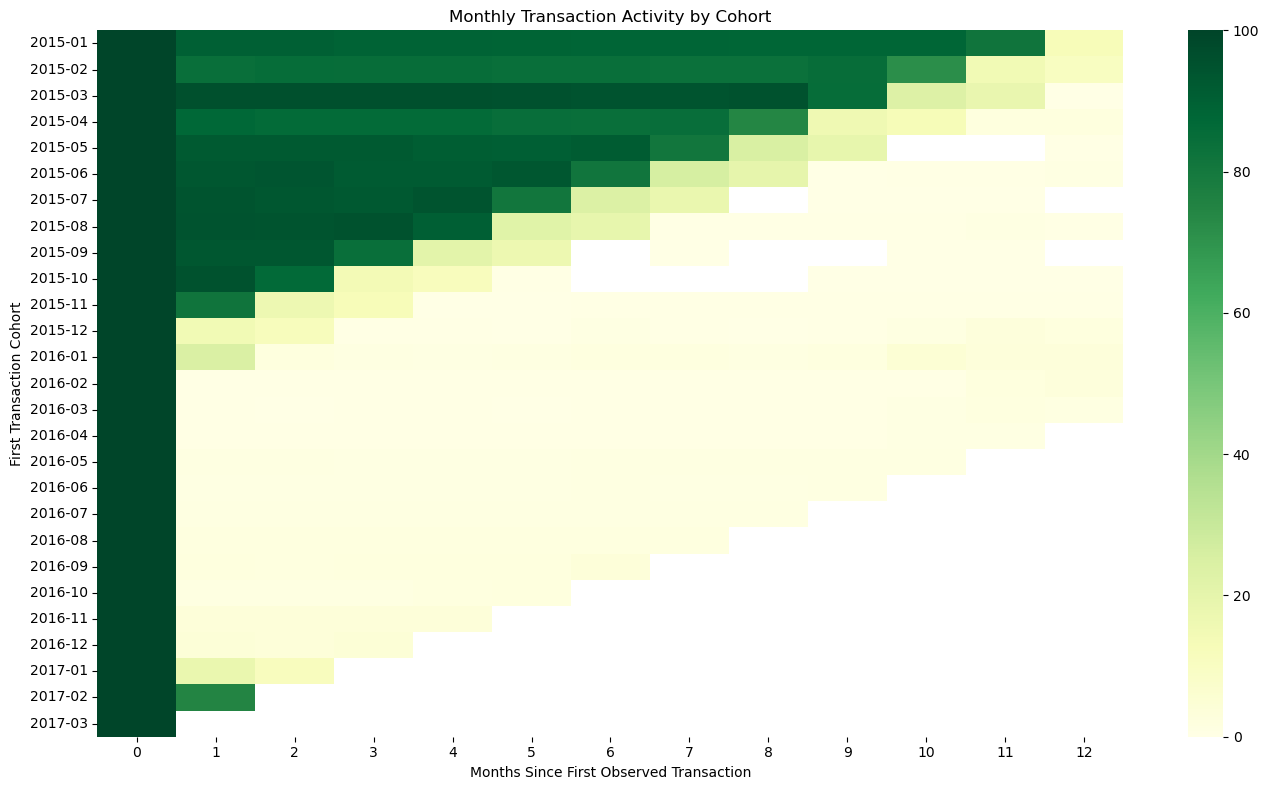

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))

sns.heatmap(
    cohort_percentages.iloc[:, :13],
    cmap="YlGn",
    vmin=0,
    vmax=100,
    annot=False
)

plt.title("Monthly Transaction Activity by Cohort")
plt.xlabel("Months Since First Observed Transaction")
plt.ylabel("First Transaction Cohort")
plt.tight_layout()
plt.show()

### Monthly Transaction Activity by Cohort

The heatmap compares monthly transaction activity across cohorts grouped by their first observed transaction month. Each cell represents the percentage of a cohort's initial customers who recorded a transaction in that month.

Earlier cohorts have longer observation periods, while recent cohorts contain fewer observed months. Transaction activity generally declines over time for several earlier cohorts, although activity can fluctuate as customers transact in later months.

This analysis measures observed transaction activity rather than confirmed subscription retention. Customers may skip transaction months and return later, so the percentages should not be interpreted as continuous retention rates.

In [56]:
key_findings = pd.DataFrame({
    "Analysis": [
        "Transaction history",
        "Gender",
        "Age group",
        "Auto-renewal",
        "Registration method",
        "City"
    ],
    "Key observation": [
        "Customers without matching transaction records had 78.74% churn.",
        "Female and male customers had similar churn rates.",
        "Younger age groups had higher observed churn.",
        "Customers with consistently enabled auto-renew had lower churn.",
        "Churn rates varied across registration-method codes.",
        "Churn rates varied across recorded city codes."
    ]
})

key_findings

,Analysis,Key observation
0,Transaction history,Customers without matching transaction records...
1,Gender,Female and male customers had similar churn ra...
2,Age group,Younger age groups had higher observed churn.
3,Auto-renewal,Customers with consistently enabled auto-renew...
4,Registration method,Churn rates varied across registration-method ...
5,City,Churn rates varied across recorded city codes.


## 2. Key Findings and Business Recommendations

### Key Findings

1. **Missing transaction history:** Customers without matching transaction records had a churn rate of 78.74%, compared with 6.20% among customers with recorded transaction history. This group warrants further investigation, as missing records may not represent an absence of all historical activity.

2. **Age and churn:** Younger customers had higher observed churn rates than older age groups. This suggests that retention strategies could be explored for younger customer segments.

3. **Auto-renewal behaviour:** Customers whose recorded transactions consistently had auto-renew enabled had a churn rate of 3.79%, compared with 30.73% among customers whose transactions did not always have auto-renew enabled.

4. **Registration method and location:** Churn rates varied across recorded registration-method and city codes. These differences may help identify customer segments for further investigation, although the codes' meanings have not been verified.

5. **Payment behaviour:** Churned customers had a higher mean average payment than retained customers, while both groups had the same median. This indicates differences in payment distributions rather than a simple relationship between payment amount and churn.

### Business Recommendations

- Investigate customers without matching transaction records and improve the completeness of customer transaction histories.
- Explore targeted retention initiatives for younger customer segments.
- Evaluate whether clearer auto-renewal settings and renewal reminders could help customers maintain subscriptions.
- Investigate differences across registration methods and city codes after verifying their meanings.
- Examine payment behaviour alongside subscription timing and renewal outcomes before making pricing or retention decisions.

### Limitations

- The analysis uses historical data and may not reflect current customer behaviour.
- Missing transaction records do not necessarily mean that a customer never transacted.
- Customer-level transaction features summarize available history and may not represent behaviour immediately before churn.
- The cohort heatmap measures observed monthly transaction activity, not confirmed subscription retention.
- The results show associations and do not establish causation.